In [ ]:
import cv2
import numpy as np

# 1. Agregar la 'r' antes de las comillas para evitar el SyntaxError
ruta = r'C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\basket\basket2_0001.jpg'

# 2. Leer la imagen usando numpy para evadir el bug de OpenCV con los acentos
buf = np.fromfile(ruta, dtype=np.uint8)
img = cv2.imdecode(buf, cv2.IMREAD_COLOR)

# 3. Validar y procesar
if img is not None:
    print(img.shape[0], img.shape[1], img.shape[2], len(img.shape))
else:
    print("Error: No se pudo cargar la imagen.")

# Convolutional Neural Networks

# Importar Librerías

In [1]:
import numpy as np
import os
import re
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [2]:
import keras
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from keras.models import Sequential,Model
from tensorflow.keras.layers import Input
from keras.layers import Dense, Dropout, Flatten
#from keras.layers import Conv2D, MaxPooling2D
#from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    BatchNormalization, SeparableConv2D, MaxPooling2D, Activation, Flatten, Dropout, Dense, Conv2D
)
from keras.layers import LeakyReLU

# Cargar set de Imágenes

In [4]:
# 1. Se eliminó os.getcwd() porque ya tienes una ruta absoluta y se agregó la 'r'
dirname = r'C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages'
imgpath = dirname + os.sep

images = []
directories = []
dircount = []
prevRoot=''
cant=0

print("leyendo imagenes de ",imgpath)

for root, dirnames, filenames in os.walk(imgpath):
    for filename in filenames:
        if re.search("\.(jpg|jpeg|png|bmp|tiff)$", filename):
            cant=cant+1
            filepath = os.path.join(root, filename)
            image = plt.imread(filepath)
            if(len(image.shape)==3):
                
                images.append(image)
            b = "Leyendo..." + str(cant)
            print (b, end="\r")
            if prevRoot !=root:
                print(root, cant)
                prevRoot=root
                directories.append(root)
                dircount.append(cant)
                cant=0
dircount.append(cant)

dircount = dircount[1:]
dircount[0]=dircount[0]+1
print('Directorios leidos:',len(directories))
print("Imagenes en cada directorio", dircount)
print('suma Total de imagenes en subdirs:',sum(dircount))

<>:15: SyntaxWarning: invalid escape sequence '\.'
<>:15: SyntaxWarning: invalid escape sequence '\.'
C:\Users\hikaf\AppData\Local\Temp\ipykernel_11708\266406917.py:15: SyntaxWarning: invalid escape sequence '\.'
  if re.search("\.(jpg|jpeg|png|bmp|tiff)$", filename):


leyendo imagenes de  C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\americano 1
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\basket 9348
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\beisball 8823
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\boxeo 7752
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\ciclismo 7125
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\f1 7533
C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\fut

# Creamos las etiquetas

In [5]:
labels=[]
indice=0
for cantidad in dircount:
    for i in range(cantidad):
        labels.append(indice)
    indice=indice+1
print("Cantidad etiquetas creadas: ",len(labels))


Cantidad etiquetas creadas:  77128


In [6]:
deportes=[]
indice=0
for directorio in directories:
    name = directorio.split(os.sep)
    print(indice , name[len(name)-1])
    deportes.append(name[len(name)-1])
    indice=indice+1

0 americano
1 basket
2 beisball
3 boxeo
4 ciclismo
5 f1
6 futbol
7 golf
8 natacion
9 tenis


In [7]:
y = np.array(labels)
X = np.array(images, dtype=np.uint8) #convierto de lista a numpy



# Find the unique numbers from the train labels
classes = np.unique(y)
nClasses = len(classes)
print('Total number of outputs : ', nClasses)
print('Output classes : ', classes)

Total number of outputs :  10
Output classes :  [0 1 2 3 4 5 6 7 8 9]


# Creamos Sets de Entrenamiento y Test

In [8]:
train_X,test_X,train_Y,test_Y = train_test_split(X,y,test_size=0.2)
print('Training data shape : ', train_X.shape, train_Y.shape)
print('Testing data shape : ', test_X.shape, test_Y.shape)

Training data shape :  (61702, 21, 28, 3) (61702,)
Testing data shape :  (15426, 21, 28, 3) (15426,)


Text(0.5, 1.0, 'Ground Truth : 0')

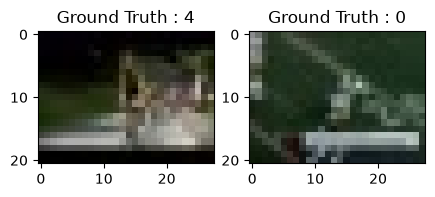

In [9]:
plt.figure(figsize=[5,5])

# Display the first image in training data
plt.subplot(121)
plt.imshow(train_X[0,:,:], cmap='gray')
plt.title("Ground Truth : {}".format(train_Y[0]))

# Display the first image in testing data
plt.subplot(122)
plt.imshow(test_X[0,:,:], cmap='gray')
plt.title("Ground Truth : {}".format(test_Y[0]))

# Preprocesamos las imagenes

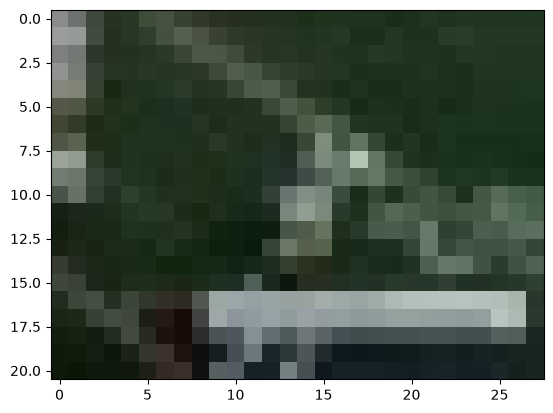

In [10]:
train_X = train_X.astype('float32')
test_X = test_X.astype('float32')
train_X = train_X/255.
test_X = test_X/255.
plt.imshow(test_X[0,:,:])

## Hacemos el One-hot Encoding para la red

In [11]:
# Change the labels from categorical to one-hot encoding
train_Y_one_hot = to_categorical(train_Y)
test_Y_one_hot = to_categorical(test_Y)

# Display the change for category label using one-hot encoding
print('Original label:', train_Y[0])
print('After conversion to one-hot:', train_Y_one_hot[0])

Original label: 4
After conversion to one-hot: [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


# Creamos el Set de Entrenamiento y Validación

In [12]:
#Mezclar todo y crear los grupos de entrenamiento y testing
train_X,valid_X,train_label,valid_label = train_test_split(train_X, train_Y_one_hot, test_size=0.2, random_state=13)

In [13]:
print(train_X.shape,valid_X.shape,train_label.shape,valid_label.shape)

(49361, 21, 28, 3) (12341, 21, 28, 3) (49361, 10) (12341, 10)


# Creamos el modelo de CNN

In [14]:
#declaramos variables con los parámetros de configuración de la red
INIT_LR = 1e-3 # Valor inicial de learning rate. El valor 1e-3 corresponde con 0.001
epochs = 50 # Cantidad de iteraciones completas al conjunto de imagenes de entrenamiento
batch_size = 32 # cantidad de imágenes que se toman a la vez en memoria

In [15]:
sport_model = Sequential()

# Bloque Convolucional 1 (Detecta bordes y colores)
sport_model.add(Conv2D(32, kernel_size=(3, 3), activation='linear', padding='same', input_shape=(21,28,3)))
sport_model.add(LeakyReLU(alpha=0.1))
sport_model.add(MaxPooling2D((2, 2), padding='same'))
sport_model.add(Dropout(0.25)) # Reducido al 25%

# Bloque Convolucional 2 (Detecta texturas y formas simples)
sport_model.add(Conv2D(64, kernel_size=(3, 3), activation='linear', padding='same')) # input_shape eliminado
sport_model.add(LeakyReLU(alpha=0.1))
sport_model.add(MaxPooling2D((2, 2), padding='same'))
sport_model.add(Dropout(0.25)) # Reducido al 25%

# Bloque Convolucional 3 (Detecta conceptos complejos: ej. una rueda, un ojo)
sport_model.add(Conv2D(128, kernel_size=(3, 3), activation='linear', padding='same')) # input_shape eliminado
sport_model.add(LeakyReLU(alpha=0.1))
sport_model.add(MaxPooling2D((2, 2), padding='same'))
sport_model.add(Dropout(0.25)) # Reducido al 25%

# Clasificador Final (Toma los conceptos y decide qué deporte es)
sport_model.add(Flatten())
sport_model.add(Dense(128, activation='linear')) # Aumentado de 32 a 128 para evitar el cuello de botella
sport_model.add(LeakyReLU(alpha=0.1))
sport_model.add(Dropout(0.5)) # Aquí sí mantenemos 50% para forzar a la red a no memorizar
sport_model.add(Dense(nClasses, activation='softmax'))

c:\Users\hikaf\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\hikaf\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [16]:
sport_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 21, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 21, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 11, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 6, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       196,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,274 (1.11 MB)

 Trainable params: 291,274 (1.11 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
sport_model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.SGD(learning_rate=INIT_LR), metrics=['accuracy'])

# Entrenamos el modelo: Aprende a clasificar imágenes

In [19]:
# este paso puede tomar varios minutos, dependiendo de tu ordenador, cpu y memoria ram libre
sport_train = sport_model.fit(train_X, train_label, batch_size=batch_size,epochs=epochs,verbose=1,validation_data=(valid_X, valid_label))

Epoch 1/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 38s 23ms/step - accuracy: 0.1329 - loss: 2.2772 - val_accuracy: 0.2587 - val_loss: 2.2514
Epoch 2/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.1891 - loss: 2.1957 - val_accuracy: 0.3486 - val_loss: 2.1266
Epoch 3/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.2549 - loss: 2.0362 - val_accuracy: 0.4699 - val_loss: 1.9072
Epoch 4/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.3532 - loss: 1.8281 - val_accuracy: 0.5958 - val_loss: 1.6142
Epoch 5/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.4552 - loss: 1.5762 - val_accuracy: 0.6452 - val_loss: 1.3393
Epoch 6/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 35s 23ms/step - accuracy: 0.5322 - loss: 1.3691 - val_accuracy: 0.6783 - val_loss: 1.1630
Epoch 7/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.5848 - loss: 1.2243 - val_accuracy: 0.6988 - val_loss: 1.0426
Epoch 8/50
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 38s 25ms/step - accuracy: 0.6222 -

In [20]:
# guardamos la red, para reutilizarla en el futuro, sin tener que volver a entrenar
sport_model.save(r"C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\Pruebas\CNN\sport.h5")

# Evaluamos la red

In [2]:
test_eval = sport_model.evaluate(test_X, test_Y_one_hot, verbose=1)

NameError: name 'sport_model' is not defined

In [22]:
print('Test loss:', test_eval[0])
print('Test accuracy:', test_eval[1])

Test loss: 0.20750872790813446
Test accuracy: 0.9314144849777222


In [23]:
sport_train.history

{'accuracy': [0.13293896615505219,
  0.18913717567920685,
  0.2548975944519043,
  0.3531532883644104,
  0.4551771581172943,
  0.5321609973907471,
  0.5848341584205627,
  0.6222118735313416,
  0.6479204297065735,
  0.6718259453773499,
  0.6914365887641907,
  0.707116961479187,
  0.7229999303817749,
  0.7340207695960999,
  0.7502076625823975,
  0.75983065366745,
  0.7710135579109192,
  0.7775774598121643,
  0.785599946975708,
  0.7926905751228333,
  0.7997609376907349,
  0.8074188232421875,
  0.8121188879013062,
  0.8160693645477295,
  0.8223293423652649,
  0.8257733583450317,
  0.8292781710624695,
  0.832560122013092,
  0.8397925496101379,
  0.8427503705024719,
  0.8468426465988159,
  0.8497802019119263,
  0.8532039523124695,
  0.8554729223251343,
  0.8584915399551392,
  0.8619558215141296,
  0.8657847046852112,
  0.8670610189437866,
  0.8706468939781189,
  0.8724296689033508,
  0.8755090236663818,
  0.8791961073875427,
  0.8818500638008118,
  0.8827617168426514,
  0.8850306868553162,
 

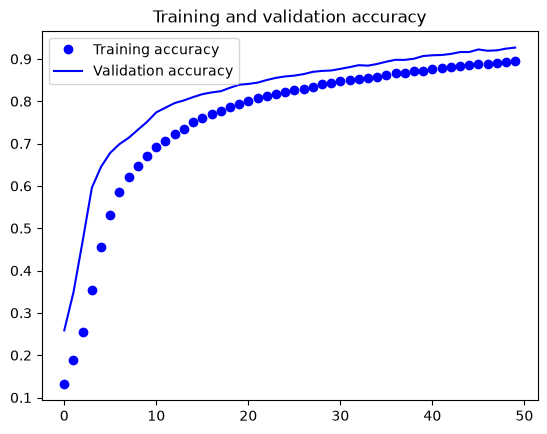

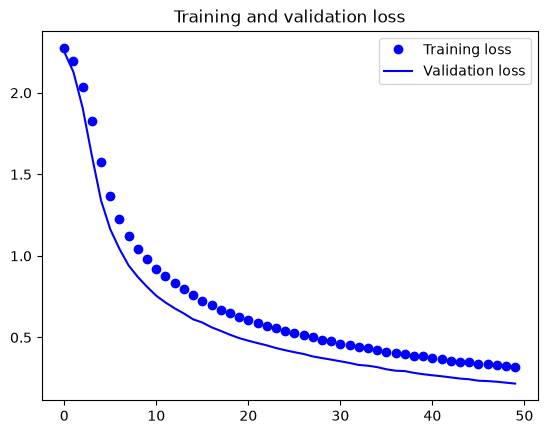

In [24]:
accuracy = sport_train.history['accuracy']
val_accuracy = sport_train.history['val_accuracy']
loss = sport_train.history['loss']
val_loss = sport_train.history['val_loss']
epochs = range(len(accuracy))
plt.plot(epochs, accuracy, 'bo', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

In [25]:
predicted_classes2 = sport_model.predict(test_X)

483/483 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step


In [26]:
predicted_classes=[]
for predicted_sport in predicted_classes2:
    predicted_classes.append(predicted_sport.tolist().index(max(predicted_sport)))
predicted_classes=np.array(predicted_classes)

In [27]:
predicted_classes.shape, test_Y.shape

((15426,), (15426,))

# Aprendamos de los errores: Qué mejorar

Found 14368 correct labels


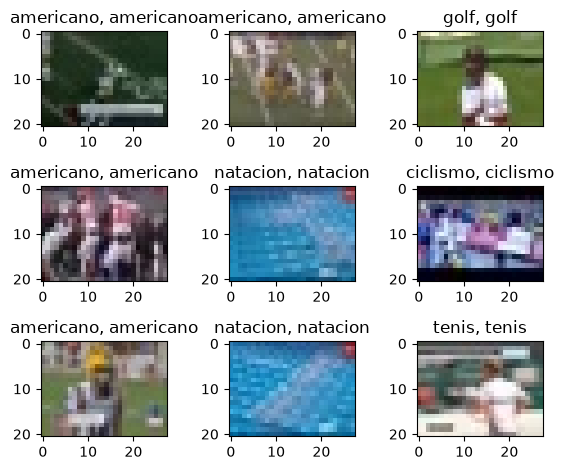

In [28]:
correct = np.where(predicted_classes==test_Y)[0]
print("Found %d correct labels" % len(correct))
for i, correct in enumerate(correct[0:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(test_X[correct].reshape(21,28,3), cmap='gray', interpolation='none')
    plt.title("{}, {}".format(deportes[predicted_classes[correct]],
                                                    deportes[test_Y[correct]]))

    plt.tight_layout()

Found 1058 incorrect labels


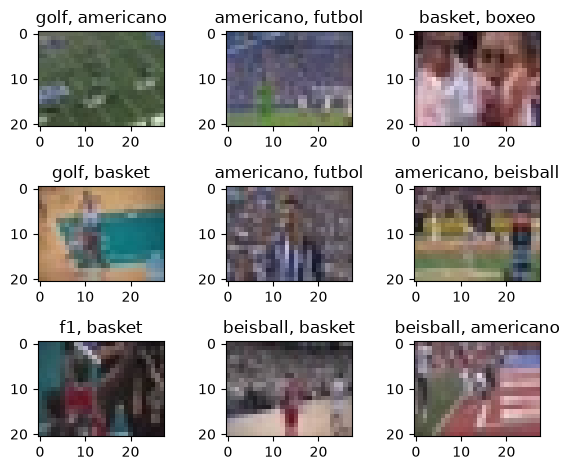

In [29]:
incorrect = np.where(predicted_classes!=test_Y)[0]
print("Found %d incorrect labels" % len(incorrect))
for i, incorrect in enumerate(incorrect[0:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(test_X[incorrect].reshape(21,28,3), cmap='gray', interpolation='none')
    plt.title("{}, {}".format(deportes[predicted_classes[incorrect]],
                                                    deportes[test_Y[incorrect]]))
    plt.tight_layout()

In [30]:
target_names = ["Class {}".format(i) for i in range(nClasses)]
print(classification_report(test_Y, predicted_classes, target_names=target_names))

              precision    recall  f1-score   support

     Class 0       0.81      0.88      0.85      1851
     Class 1       0.96      0.95      0.95      1765
     Class 2       0.92      0.88      0.90      1533
     Class 3       0.97      0.99      0.98      1419
     Class 4       0.99      1.00      1.00      1533
     Class 5       0.87      0.70      0.77      1038
     Class 6       0.99      0.93      0.96      1522
     Class 7       0.88      0.96      0.92      1987
     Class 8       0.97      0.97      0.97      1042
     Class 9       0.99      1.00      0.99      1736

    accuracy                           0.93     15426
   macro avg       0.94      0.92      0.93     15426
weighted avg       0.93      0.93      0.93     15426



In [3]:
import cv2
import numpy as np
from skimage.transform import resize
import tensorflow as tf

# 1. Cargar el modelo que ya habías entrenado y guardado
ruta_modelo = r'C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\Pruebas\CNN\sport.h5'
sport_model = tf.keras.models.load_model(ruta_modelo)

# 2. Definir la lista de deportes (el orden debe ser exactamente el mismo de tu entrenamiento)
deportes = ['americano', 'natacion', 'futbol', 'beisball', 'f1', 'ciclismo', 'golf', 'boxeo', 'tenis', 'basket']

images = []

# 3. Especificar la ruta absoluta completa con la 'r'
filenames = [r'C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\golf\golf_0113.jpg'] 

for filepath in filenames:
    buf = np.fromfile(filepath, dtype=np.uint8)
    image = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    
    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image_resized = resize(image, (21, 28), anti_aliasing=True, clip=False, preserve_range=True)
        images.append(image_resized)
    else:
        print(f"Error: No se pudo cargar {filepath}")

if len(images) > 0:
    X = np.array(images, dtype=np.uint8)
    test_X = X.astype('float32')
    test_X = test_X / 255.
    
    # 4. Hacer la predicción con el modelo cargado
    predicted_classes = sport_model.predict(test_X)
    
    # 5. Mostrar los resultados
    for i, img_tagged in enumerate(predicted_classes):
        clase_indice = img_tagged.tolist().index(max(img_tagged))
        print(f"Archivo: {filenames[i]}")
        print(f"Predicción: {deportes[clase_indice]}")
        print(f"Confianza: {max(img_tagged) * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step
Archivo: C:\Users\hikaf\OneDrive - Instituto Tecnológico de Morelia\Documentos\Tec\9°\Inteligencia Artificial\sportimages\golf\golf_0113.jpg
Predicción: boxeo
Confianza: 96.37%
